In [42]:
import numpy as np
import matplotlib.pyplot as plt
import math


n_cells = 300

# t_final = 1.0e-4
t_final = 1.0e-4

x = np.linspace(0, 1, n_cells+1)
x_center = 0.5 * (x[:-1] + x[1:])
h = x[1] - x[0]

x0 = 0.90

ion_density = 1.0e19
ion_velocity = 100
ion_temperature = 1

K_cx = 3.2e-15 * np.sqrt(ion_temperature/0.026)
collision_rate = K_cx * ion_density

BGK_stddev = np.sqrt(ion_temperature * 1.602176634e-19 / 1.67e-27)

D = BGK_stddev**2 / collision_rate

R = 1


print('Collision rate: ', collision_rate)
print('Average collision time: ', 1/collision_rate)

print('Expected deviation: ', np.sqrt(2*D*t_final))
print('99.9 range: ', 2 * 2.6 * np.sqrt(2*D*t_final))
print(x)

Collision rate:  198455.57534273353
Average collision time:  5.038911092686593e-06
Expected deviation:  0.3109426582003393
99.9 range:  1.6169018226417644
[0.         0.00333333 0.00666667 0.01       0.01333333 0.01666667
 0.02       0.02333333 0.02666667 0.03       0.03333333 0.03666667
 0.04       0.04333333 0.04666667 0.05       0.05333333 0.05666667
 0.06       0.06333333 0.06666667 0.07       0.07333333 0.07666667
 0.08       0.08333333 0.08666667 0.09       0.09333333 0.09666667
 0.1        0.10333333 0.10666667 0.11       0.11333333 0.11666667
 0.12       0.12333333 0.12666667 0.13       0.13333333 0.13666667
 0.14       0.14333333 0.14666667 0.15       0.15333333 0.15666667
 0.16       0.16333333 0.16666667 0.17       0.17333333 0.17666667
 0.18       0.18333333 0.18666667 0.19       0.19333333 0.19666667
 0.2        0.20333333 0.20666667 0.21       0.21333333 0.21666667
 0.22       0.22333333 0.22666667 0.23       0.23333333 0.23666667
 0.24       0.24333333 0.24666667 0.25   

In [43]:
# simulate using monte carlo

n_cells_mc = 300
n_particles = 100000
density_mc = np.zeros(n_cells_mc, dtype=float)
x_mc = np.linspace(0, 1, n_cells_mc+1)
x_center_mc = 0.5 * (x_mc[:-1] + x_mc[1:])
for i in range(n_particles):
    x_particle = x0
    t = 0
    v = np.random.normal(ion_velocity, BGK_stddev)
    weight  = 1.0

    while t < t_final:
        # time till next collision
        eps = np.random.rand()
        tc = -np.log(eps) / collision_rate
        tc = min(tc, t_final - t)

        # calculate time till boundary hit
        t_boundary = np.inf
        if v > 0:
            t_boundary = (1 - x_particle) / v
        elif v < 0:
            t_boundary = x_particle / -v

        if t_boundary < tc:
            # move particle to boundary
            x_particle += v * t_boundary
            v = -v
            t += t_boundary
            weight *= R
            if(weight < 0.00001):
                break
            continue

        # move particle
        x_particle += v * tc
        # draw new velocity
        v = np.random.normal(ion_velocity, BGK_stddev)
        t += tc

    # tally final position
    x_index = int(x_particle * n_cells_mc)
    volume = 1/(n_cells_mc)
    density_mc[x_index] += 1/volume / n_particles * weight

In [44]:
# Simulate brownian motion

n_cells_mc = 300
n_particles = 10000
density_bm = np.zeros(n_cells_mc, dtype=float)
dt = 1.0e-7

for i in range(n_particles):
    x_particle = x0
    t = 0
    weight  = 1.0

    while t < t_final:

        dt2 = min(dt, t_final - t)

        x_particle += dt2 * ion_velocity + np.sqrt(2*D*dt2) * np.random.normal(0,1)

        if x_particle < 0:
            x_particle = -x_particle
            weight *= R
            if(weight < 0.00001):
                break
            continue
        elif x_particle > 1:
            x_particle = 2 - x_particle
            weight *= R
            if(weight < 0.00001):
                break
            continue

        t += dt2

    # tally final position
    x_index = int(x_particle * n_cells_mc)
    volume = 1/(n_cells_mc)
    density_bm[x_index] += 1/volume / n_particles * weight

In [ ]:
# Analytical model

density_analytical = np.zeros(n_cells)

# calculate reflection coefficient so that flux is zero at x = 1

alpha = (1. - R)
beta = R


dist = 1 - x0

A = - (alpha - beta * dist / (2 * D * t_final)) / (alpha + beta * dist / (2 * D * t_final))

# A = np.exp(2.*ion_velocity * (1 - x0) / (2 * D))

# A = - (1 - x0 - ion_velocity * t_final) / (x0 - 1 - ion_velocity * t_final) * np.exp( - 2 * ion_velocity * (1 - x0) / (2 * D) )

A = np.exp( - 2 * ion_velocity * (1 - x0) / (2 * D) )

print('A: ', A)

for i in range(n_cells):
    x_center = (i + 0.5) / n_cells
    density_analytical[i] = np.exp( -( x_center - x0 - ion_velocity * t_final )**2/ (4*D*t_final) ) / np.sqrt(4*np.pi*D*t_final) + A * np.exp( -( x_center + x0 - 2 - ion_velocity * t_final )**2/ (4*D*t_final) ) / np.sqrt(4*np.pi*D*t_final)


x_center = 0.5 * (x[:-1] + x[1:])


x_larger = np.linspace(0, 2, 2*n_cells+1)
x_center = 0.5 * (x_larger[:-1] + x_larger[1:])
density_no_boundary

plt.stairs(density_mc, x_mc, label='Kinetic (MC)')
plt.stairs(density_bm, x_mc, label='Brownian motion')
plt.plot(x_center, density_analytical, label='Fluid (Analytical)', linestyle='--')
plt.legend()
plt.xlabel('x')
plt.ylabel('density')
plt.title('Neutral density at t = 0.01ms with reflecting boundary')
plt.show()

A:  0.9795268206594911


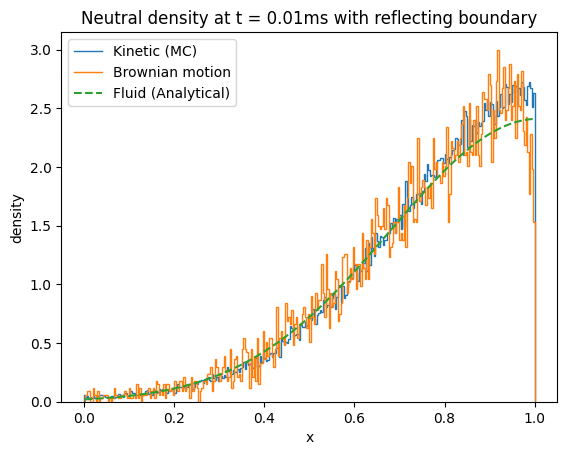

In [65]:

x_center = 0.5 * (x[:-1] + x[1:])

plt.stairs(density_mc, x_mc, label='Kinetic (MC)')
plt.stairs(density_bm, x_mc, label='Brownian motion')
# plt.stairs(density_fluid, x, label='Finite Difference')
# plt.stairs(density_analytical, x, label='Analytical')
# plt.plot(x_center, density_fluid, label='Finite Difference')
plt.plot(x_center, density_analytical, label='Fluid (Analytical)', linestyle='--')
plt.legend()
plt.xlabel('x')
plt.ylabel('density')
plt.title('Neutral density at t = 0.01ms with reflecting boundary')
plt.show()